# Logistic Regression vs Random Forest – Applying Probability and Statistics to Evaluate an ML Model

**Authors:** Abhay Burye, Jalesh Kumar, Uttam K  
**Dataset:** [Kaggle – Weather Type Classification](https://www.kaggle.com/datasets/nikhil7280/weather-type-classification)  
**Repository:** https://github.com/uttamk1/APS-PROJECT

**Research question:** Does the improved model (Random Forest) perform better than the baseline (Logistic Regression), or could the observed difference be due to variation in the test sample?

Everything is seeded (`SEED = 42`), so *Run all* reproduces the same numbers. Put `weather_classification_data.csv` in the same folder as this notebook (or it is downloaded with `kagglehub`).

## 0. Imports, settings and helper functions

In [1]:
import argparse
import glob
import os
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

SEED = 42            # global random seed: split, models and bootstrap are reproducible
ALPHA = 0.05         # significance level for the hypothesis tests
TARGET = "Weather Type"
CSV_NAME = "weather_classification_data.csv"
KAGGLE_ID = "nikhil7280/weather-type-classification"


# --------------------------------------------------------------------------------------
# 1. Data loading
# --------------------------------------------------------------------------------------
def load_dataset(path=None):
    """Load the CSV from --data, the working folder, or Kaggle (kagglehub)."""
    candidates = [path] if path else glob.glob(CSV_NAME) + glob.glob("*weather*.csv")
    for p in candidates:
        if p and os.path.exists(p):
            print(f"Loaded local file: {p}")
            return pd.read_csv(p)
    try:
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_ID)
        files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        print(f"Downloaded from Kaggle: {files[0]}")
        return pd.read_csv(files[0])
    except Exception as e:
        raise SystemExit(
            f"Could not find or download the dataset ({e}).\n"
            f"Download {CSV_NAME} from https://www.kaggle.com/datasets/{KAGGLE_ID} and either put it "
            f"next to this script or pass --data <path>.")


# --------------------------------------------------------------------------------------
# 2. Cleaning
# --------------------------------------------------------------------------------------
def clean(df_raw):
    print(f"\nRaw shape: {df_raw.shape}")
    print("Missing values per column:\n", df_raw.isna().sum().to_string())
    df = df_raw.drop_duplicates().reset_index(drop=True)
    print(f"\nRows after removing duplicates: {len(df)} (removed {len(df_raw) - len(df)})")

    # Humidity and precipitation are percentages: values outside 0-100 are impossible.
    # They become NaN and are later imputed with the TRAINING median inside the pipeline.
    pct_cols = [c for c in df.columns if "Humidity" in c or "Precipitation" in c]
    for c in pct_cols:
        bad = (df[c] > 100) | (df[c] < 0)
        print(f"{c}: {int(bad.sum())} implausible values (outside 0-100) -> set to NaN")
        df.loc[bad, c] = np.nan
    return df, pct_cols


# --------------------------------------------------------------------------------------
# 3. Exploratory statistics
# --------------------------------------------------------------------------------------
def describe(df, y, num_cols, out):
    desc = pd.DataFrame({
        "mean": df[num_cols].mean(), "median": df[num_cols].median(),
        "variance": df[num_cols].var(), "std": df[num_cols].std(),
        "min": df[num_cols].min(), "max": df[num_cols].max(),
        "skewness": df[num_cols].skew()}).round(3)
    desc.to_csv(f"{out}/descriptive_statistics.csv")
    print("\nDescriptive statistics:\n", desc.to_string())
    print("\nClass counts:\n", y.value_counts().to_string())

    fig, ax = plt.subplots(figsize=(6, 4))
    counts = y.value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="Set2")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title("Class distribution"); ax.set_ylabel("Count"); ax.set_ylim(0, counts.max() * 1.2)
    plt.tight_layout(); plt.savefig(f"{out}/class_distribution.png", dpi=150); plt.show()

    n, cols = len(num_cols), 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    for ax, c in zip(axes.ravel(), num_cols):
        sns.histplot(df[c].dropna(), kde=True, ax=ax, color="steelblue"); ax.set_title(c)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{out}/histograms.png", dpi=150); plt.show()

    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    for ax, c in zip(axes.ravel(), num_cols):
        sns.boxplot(data=df, x=TARGET, y=c, ax=ax, palette="Set2"); ax.set_title(f"{c} by weather type")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{out}/boxplots_by_class.png", dpi=150); plt.show()

    plt.figure(figsize=(8, 6))
    sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Pearson correlation between numeric features")
    plt.tight_layout(); plt.savefig(f"{out}/correlation_heatmap.png", dpi=150); plt.show()


# --------------------------------------------------------------------------------------
# 4-5. Models
# --------------------------------------------------------------------------------------
def make_preprocessor(num_cols, cat_cols, scale=False):
    """Median imputation for numbers, mode imputation + one-hot for categories.
    Fitted inside each pipeline on training data only, so the test set never leaks in."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:                                   # linear models need features on the same scale
        num_steps.append(("scale", StandardScaler()))
    num_pipe = Pipeline(num_steps)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])


def make_baseline(num_cols, cat_cols):
    """Baseline: multinomial Logistic Regression (a simple linear model)."""
    return Pipeline([("prep", make_preprocessor(num_cols, cat_cols, scale=True)),
                     ("clf", LogisticRegression(max_iter=2000))])


def make_gb(num_cols, cat_cols, **params):
    return Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                     ("clf", HistGradientBoostingClassifier(random_state=SEED, **params))])


def make_improved(kind, num_cols, cat_cols, **params):
    return (make_rf if kind == "Random Forest" else make_gb)(num_cols, cat_cols, **params)


def make_rf(num_cols, cat_cols, **params):
    return Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                     ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **params))])


def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Macro precision": precision_score(y_true, y_pred, average="macro"),
            "Macro recall": recall_score(y_true, y_pred, average="macro"),
            "Macro F1": f1_score(y_true, y_pred, average="macro")}




# --------------------------------------------------------------------------------------
# 7. Confidence intervals and sampling
# --------------------------------------------------------------------------------------
Z95 = stats.norm.ppf(0.975)   # 1.96


def normal_ci(p, n):
    """95% CI for a proportion (accuracy): p +/- 1.96 * sqrt(p(1-p)/n)."""
    se = np.sqrt(p * (1 - p) / n)
    return p - Z95 * se, p + Z95 * se, se


def diff_ci(p1, p2, n1, n2):
    """95% CI for the difference of two proportions p2 - p1."""
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    d = p2 - p1
    return d - Z95 * se, d + Z95 * se, se


def bootstrap_accuracy(correct_dt, correct_rf, n_boot, rng):
    """Draw n_boot samples of the test set WITH replacement and record both accuracies."""
    n = len(correct_dt)
    acc_dt, acc_rf = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        acc_dt[b] = correct_dt[idx].mean()
        acc_rf[b] = correct_rf[idx].mean()
    return acc_dt, acc_rf


# --------------------------------------------------------------------------------------
# 8. Hypothesis test: two-proportion z-test
# --------------------------------------------------------------------------------------
def two_proportion_z_test(x1, n1, x2, n2):
    """H0: p1 = p2 (both models have the same accuracy).  H1: p1 != p2.
    z = (p2 - p1) / sqrt(p(1-p)(1/n1 + 1/n2)), where p is the pooled proportion."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    p_two = 2 * stats.norm.sf(abs(z))
    p_one = stats.norm.sf(z)          # H1: p2 > p1 (improved model better)
    return z, p_two, p_one


# --------------------------------------------------------------------------------------
# Main
# --------------------------------------------------------------------------------------

%matplotlib inline

In [2]:
from types import SimpleNamespace
args = SimpleNamespace(data="weather_classification_data.csv", boot=2000, splits=10, out="outputs")
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
out = args.out
os.makedirs(out, exist_ok=True)

## 1–2. Load and clean the data
Duplicates are removed; humidity/precipitation values outside 0–100 % are impossible and are set to missing (imputed later with the **training median** inside the pipeline).

In [3]:
# 1-2. Load and clean ---------------------------------------------------------------
df, pct_cols = clean(load_dataset(args.data))
X, y = df.drop(columns=[TARGET]), df[TARGET]
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("\nNumeric features:", num_cols, "\nCategorical features:", cat_cols)

Loaded local file: weather_classification_data.csv

Raw shape: (13200, 11)
Missing values per column:
 Temperature             0
Humidity                0
Wind Speed              0
Precipitation (%)       0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility (km)         0
Location                0
Weather Type            0

Rows after removing duplicates: 13200 (removed 0)
Humidity: 416 implausible values (outside 0-100) -> set to NaN
Precipitation (%): 392 implausible values (outside 0-100) -> set to NaN

Numeric features: ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)'] 
Categorical features: ['Cloud Cover', 'Season', 'Location']


## 3. Exploratory statistics
Mean, median, variance, standard deviation and skewness of each numeric feature, the class balance, distributions, box plots by class and the correlation matrix.


Descriptive statistics:
                           mean   median  variance     std     min      max  skewness
Temperature             19.128    21.00   302.284  17.386  -25.00   109.00     0.222
Humidity                67.524    69.00   376.212  19.396   20.00   100.00    -0.503
Wind Speed               9.832     9.00    47.730   6.909    0.00    48.50     1.360
Precipitation (%)       52.073    56.00   968.434  31.120    0.00   100.00    -0.157
Atmospheric Pressure  1005.828  1007.65  1383.809  37.200  800.12  1199.21    -0.294
UV Index                 4.006     3.00    14.873   3.857    0.00    14.00     0.900
Visibility (km)          5.463     5.00    11.367   3.371    0.00    20.00     1.233

Class counts:
 Weather Type
Rainy     3300
Cloudy    3300
Sunny     3300
Snowy     3300


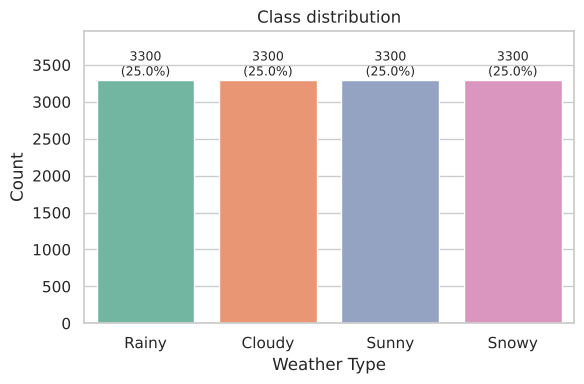

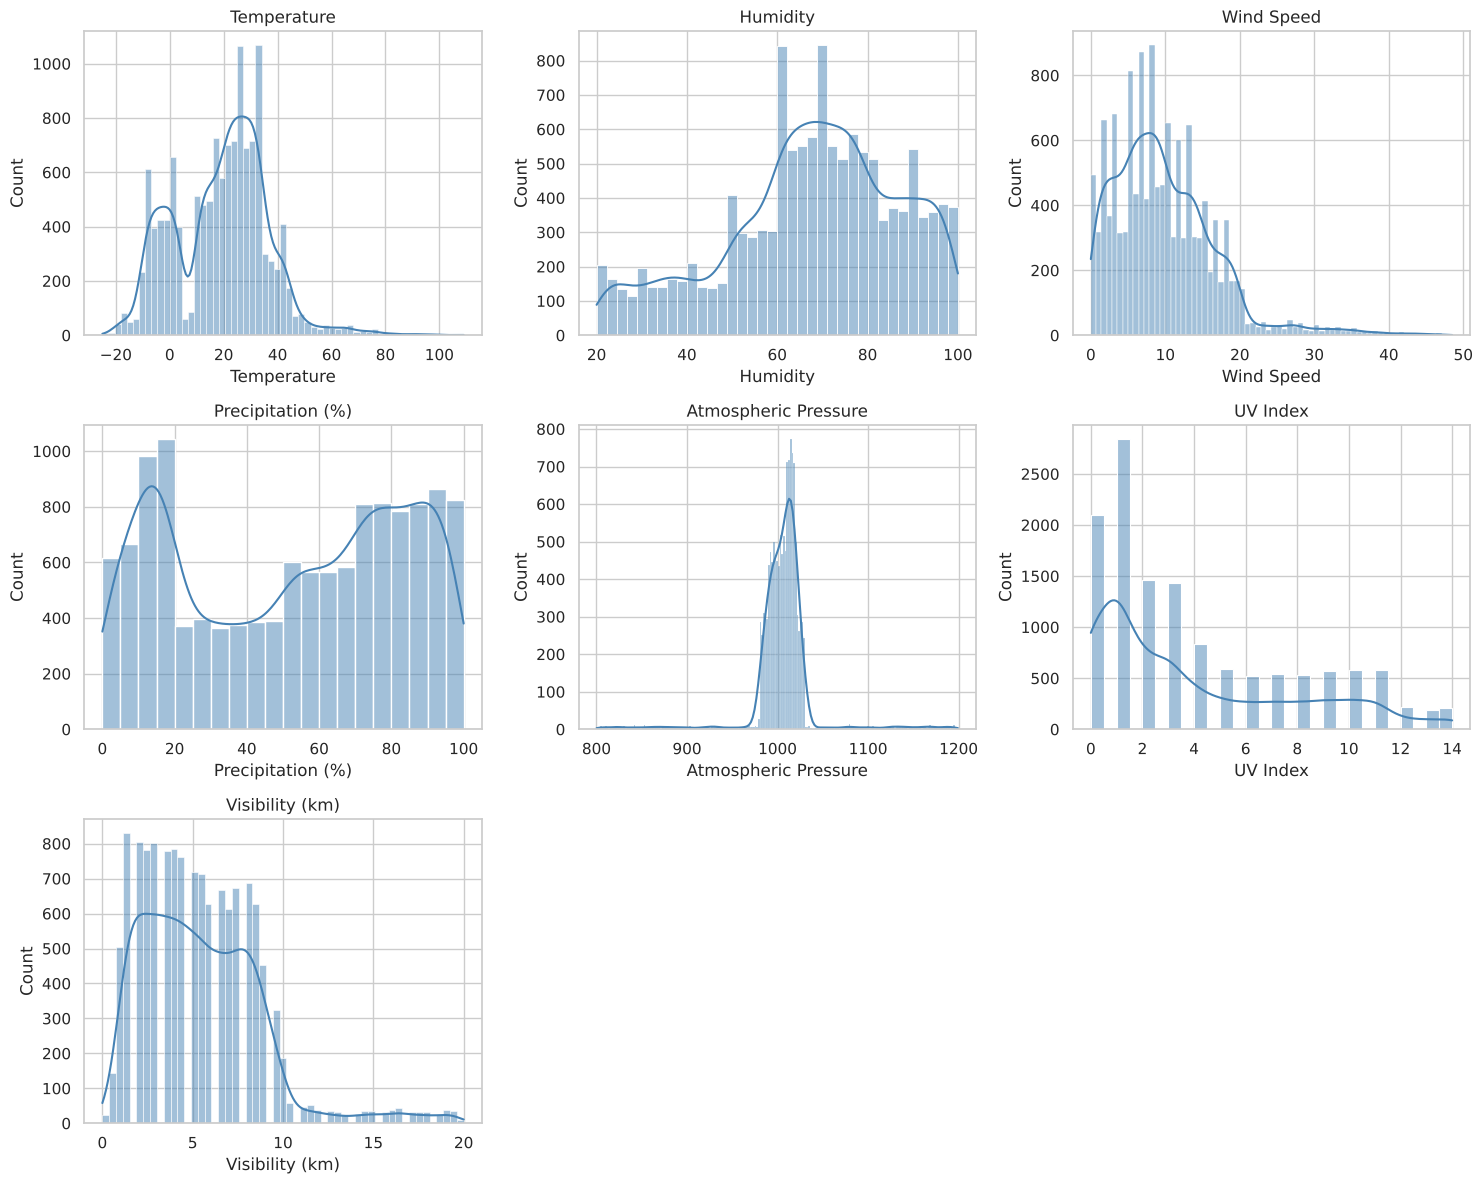

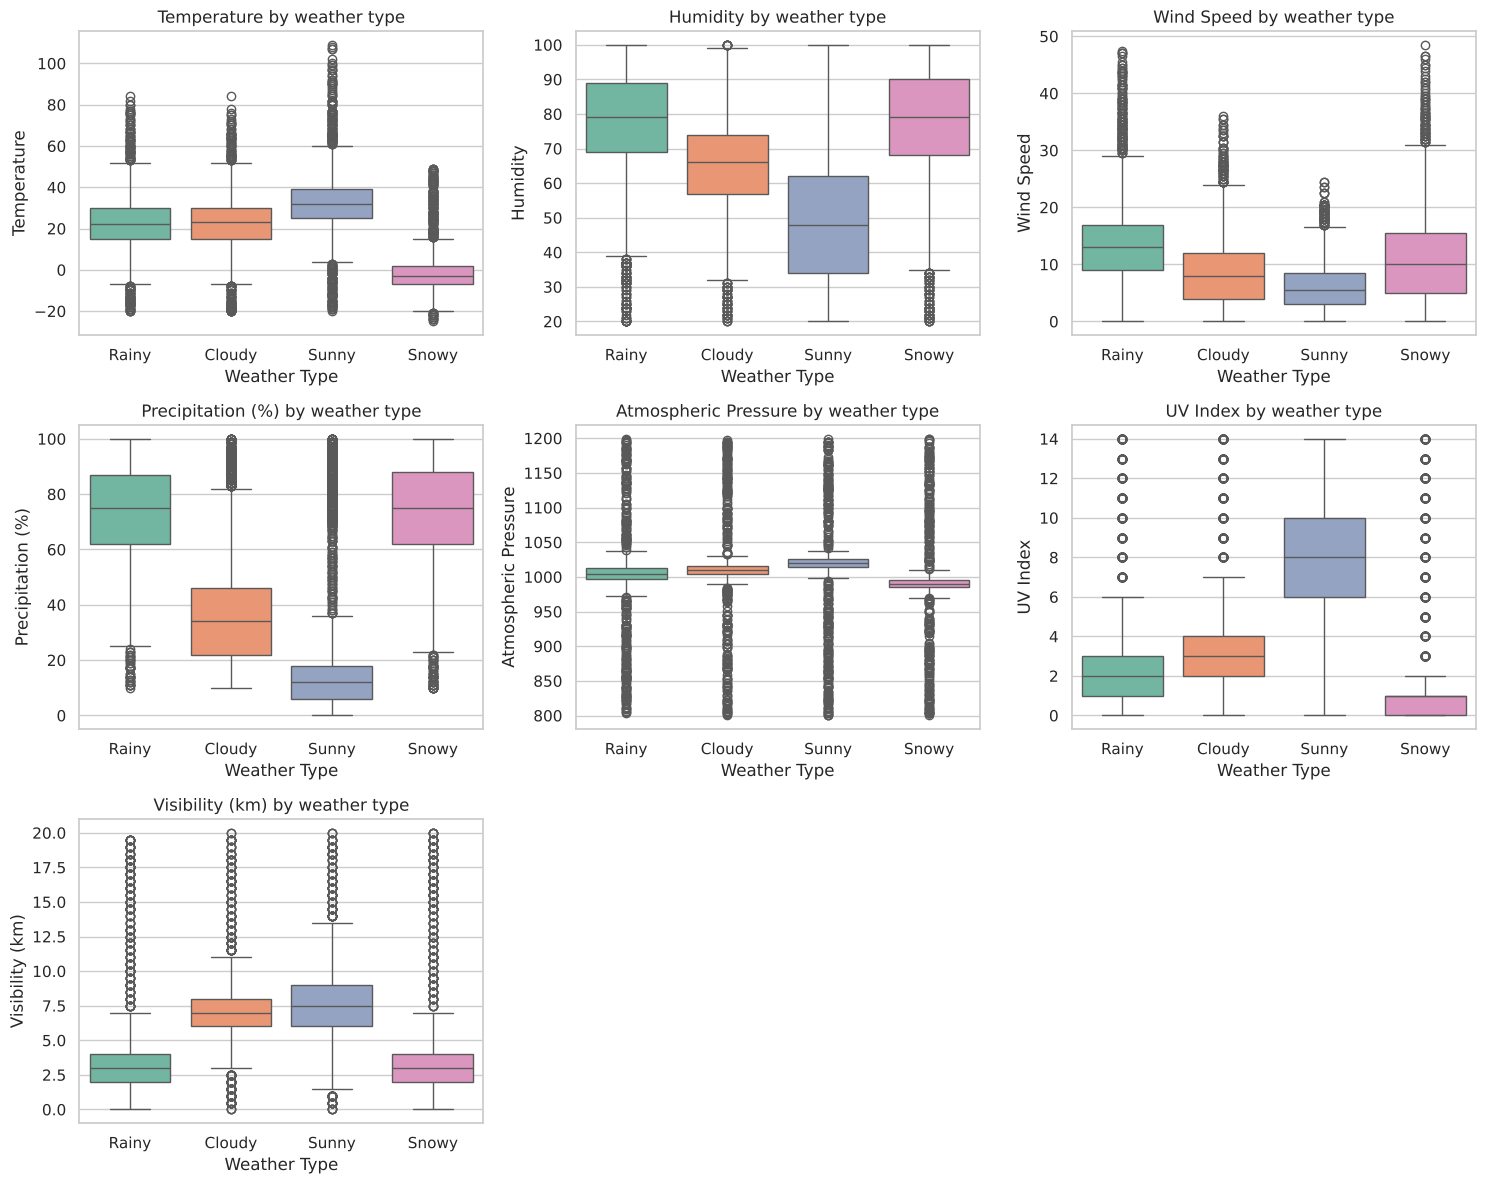

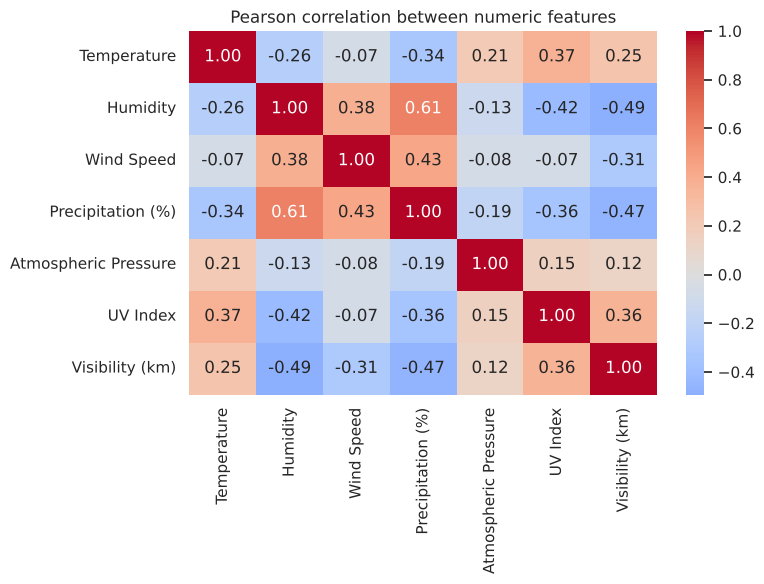

In [4]:
# 3. EDA ----------------------------------------------------------------------------
describe(df, y, num_cols, out)

## 4. Stratified train–test split
80 % train / 20 % test, stratified by weather type. **Both models are evaluated on exactly the same 2,640 test rows.**

In [5]:
# 4. One stratified held-out test set used by BOTH models ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"\nTrain: {X_train.shape}  Test: {X_test.shape}")
print(pd.DataFrame({"train %": y_train.value_counts(normalize=True).round(3),
                    "test %": y_test.value_counts(normalize=True).round(3)}).to_string())


Train: (10560, 10)  Test: (2640, 10)
              train %  test %
Weather Type                 
Cloudy           0.25    0.25
Rainy            0.25    0.25
Snowy            0.25    0.25
Sunny            0.25    0.25


## 5A. Baseline model — Logistic Regression

In [6]:
# 5A. Baseline: Logistic Regression --------------------------------------------------
dt_model = make_baseline(num_cols, cat_cols).fit(X_train, y_train)
print("\nBaseline Logistic Regression trained.")


Baseline Logistic Regression trained.


## 5B. Improved model — Random Forest
Tuned with 5-fold stratified cross-validation **on the training set only**; the test set is not touched.

*Set `TUNE = True` to re-run the full grid search (slow); the default uses the settings the search selected (200 trees, max depth 20, min 1 sample per leaf), which gives identical results.*

In [7]:
# 5B. Improved: tune a Random Forest and a Gradient Boosting model with 5-fold stratified CV
#     on the training set only, and keep whichever has the higher mean CV accuracy.
# TUNE = True re-runs the full grid search (slow: 5-15 min on Colab).
# TUNE = False uses the settings the search already chose (same results, a few seconds).
TUNE = False

if TUNE:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    candidates = {
        "Random Forest": (make_rf(num_cols, cat_cols),
                          {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 20],
                           "clf__min_samples_leaf": [1, 2]}),
        "Gradient Boosting": (make_gb(num_cols, cat_cols),
                              {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [None, 6],
                               "clf__max_iter": [200, 400]}),
    }
    searches = {}
    for name, (pipe, grid) in candidates.items():
        searches[name] = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
        print(f"{name}: best params {searches[name].best_params_} | "
              f"mean 5-fold CV accuracy = {searches[name].best_score_:.4f}")
    base_cv = cross_val_score(make_baseline(num_cols, cat_cols), X_train, y_train, cv=cv, scoring="accuracy")
    print(f"Logistic Regression: mean 5-fold CV accuracy = {base_cv.mean():.4f}")
    improved_kind = max(searches, key=lambda k: searches[k].best_score_)
    rf_model = searches[improved_kind].best_estimator_
    best_rf_params = {k.replace("clf__", ""): v for k, v in searches[improved_kind].best_params_.items()}
    print(f"Improved model chosen by CV: {improved_kind} {best_rf_params}")
else:
    best_rf_params = {"n_estimators": 200, "max_depth": 20, "min_samples_leaf": 1}
    rf_model = make_rf(num_cols, cat_cols, **best_rf_params).fit(X_train, y_train)
    improved_kind = "Random Forest"
    print("Using the tuned settings:", best_rf_params)

Using the tuned settings: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 1}


## 6. Evaluation on the same held-out test set


Point estimates on the held-out test set:
                    Baseline (Logistic Regression)  Improved model  Difference (Improved - Baseline)
Accuracy                                   0.8667          0.9121                            0.0455
Balanced accuracy                          0.8667          0.9121                            0.0455
Macro precision                            0.8676          0.9136                            0.0460
Macro recall                               0.8667          0.9121                            0.0455
Macro F1                                   0.8668          0.9124                            0.0456

=== Baseline ===
               precision    recall  f1-score   support

      Cloudy     0.8209    0.8333    0.8271       660
       Rainy     0.8453    0.8530    0.8492       660
       Snowy     0.8830    0.9152    0.8988       660
       Sunny     0.9210    0.8652    0.8922       660

    accuracy                         0.8667      2640
   macro av

=== Improved model ===
               precision    recall  f1-score   support

      Cloudy     0.8734    0.9197    0.8959       660
       Rainy     0.8869    0.9152    0.9008       660
       Snowy     0.9476    0.9045    0.9256       660
       Sunny     0.9464    0.9091    0.9274       660

    accuracy                         0.9121      2640
   macro avg     0.9136    0.9121    0.9124      2640
weighted avg     0.9136    0.9121    0.9124      2640



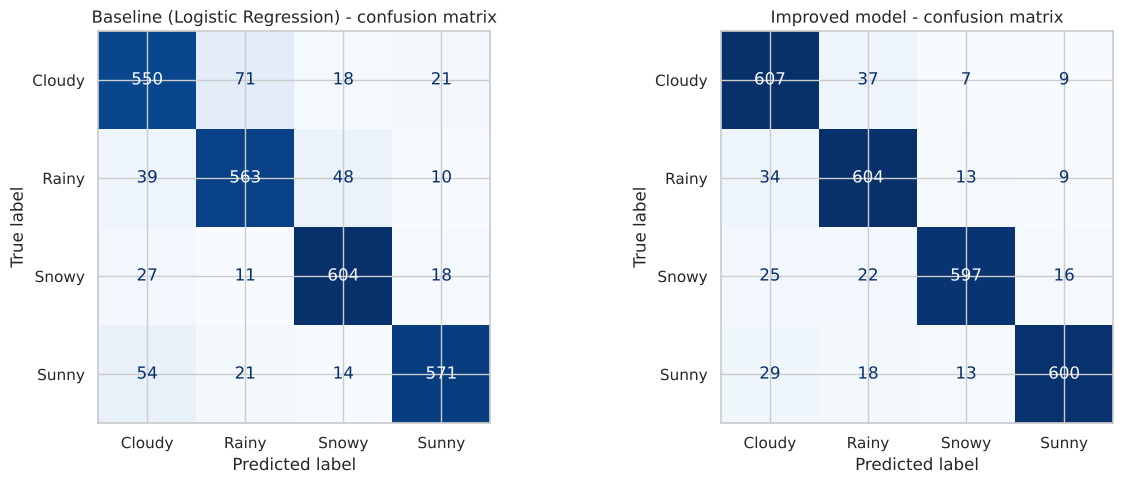

In [8]:
# 6. Evaluation on the same test set -----------------------------------------------
y_pred_dt, y_pred_rf = dt_model.predict(X_test), rf_model.predict(X_test)
labels = sorted(y.unique())
point = pd.DataFrame({"Baseline (Logistic Regression)": metrics(y_test, y_pred_dt),
                      "Improved model": metrics(y_test, y_pred_rf)})
point["Difference (Improved - Baseline)"] = point["Improved model"] - point["Baseline (Logistic Regression)"]
point.round(4).to_csv(f"{out}/point_metrics.csv")
print("\nPoint estimates on the held-out test set:\n", point.round(4).to_string())
print("\n=== Baseline ===\n", classification_report(y_test, y_pred_dt, digits=4))
print("=== Improved model ===\n", classification_report(y_test, y_pred_rf, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, name in zip(axes, [y_pred_dt, y_pred_rf], ["Baseline (Logistic Regression)", "Improved model"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels),
                           display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} - confusion matrix")
plt.tight_layout(); plt.savefig(f"{out}/confusion_matrices.png", dpi=150); plt.show()

## 7. Sampling and confidence intervals
* **Normal approximation:** accuracy is a proportion, so SE = √(p(1−p)/n) and the 95 % CI is p ± 1.96·SE.
* **Bootstrap:** resample the test set with replacement 2,000 times and take the middle 95 % of the accuracies.


Test set size n = 2640. Correct: Baseline 2288, Improved 2408
Baseline accuracy 0.8667  SE 0.0066  95% CI [0.8537, 0.8796]
Improved model accuracy 0.9121  SE 0.0055  95% CI [0.9013, 0.9229]
Difference (Improved - Baseline)   +0.0455  SE 0.0086  95% CI [+0.0286, +0.0623]

Bootstrap (B = 2000) 95% CIs: Baseline [0.8530, 0.8799] | Improved [0.9011, 0.9227] | difference [+0.0352, +0.0564]


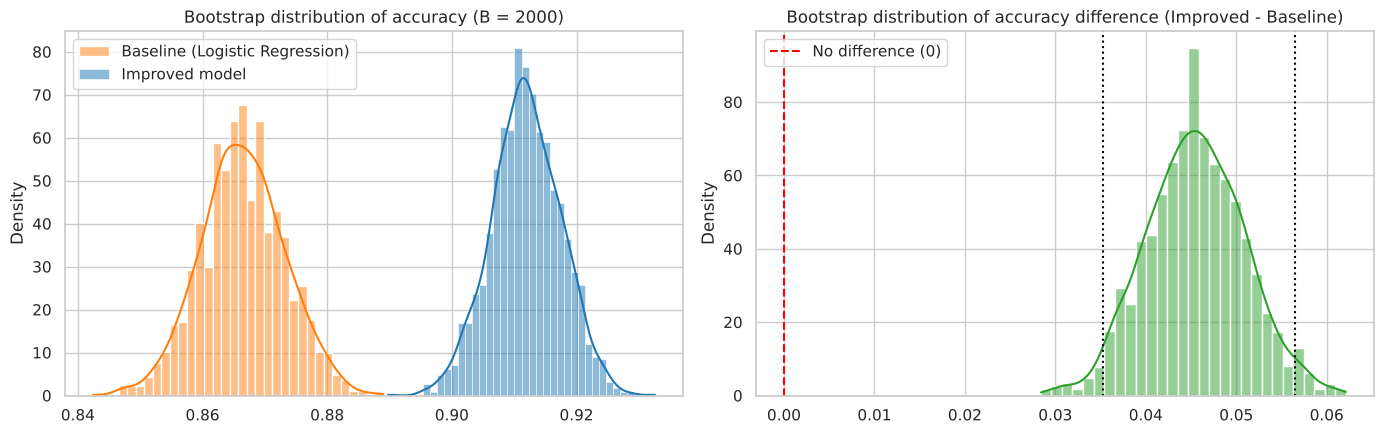

In [9]:
# 7. Sampling and confidence intervals ----------------------------------------------
correct_dt = (y_pred_dt == y_test.to_numpy())
correct_rf = (y_pred_rf == y_test.to_numpy())
n = len(y_test)
x_dt, x_rf = int(correct_dt.sum()), int(correct_rf.sum())
acc_dt, acc_rf = x_dt / n, x_rf / n
diff = acc_rf - acc_dt

lo_dt, hi_dt, se_dt = normal_ci(acc_dt, n)
lo_rf, hi_rf, se_rf = normal_ci(acc_rf, n)
lo_d, hi_d, se_d = diff_ci(acc_dt, acc_rf, n, n)
print(f"\nTest set size n = {n}. Correct: Baseline {x_dt}, Improved {x_rf}")
print(f"Baseline accuracy {acc_dt:.4f}  SE {se_dt:.4f}  95% CI [{lo_dt:.4f}, {hi_dt:.4f}]")
print(f"Improved model accuracy {acc_rf:.4f}  SE {se_rf:.4f}  95% CI [{lo_rf:.4f}, {hi_rf:.4f}]")
print(f"Difference (Improved - Baseline)   {diff:+.4f}  SE {se_d:.4f}  95% CI [{lo_d:+.4f}, {hi_d:+.4f}]")

# Bootstrap sampling: how much would accuracy change with a different test sample?
rng = np.random.default_rng(SEED)
b_dt, b_rf = bootstrap_accuracy(correct_dt, correct_rf, args.boot, rng)
b_diff = b_rf - b_dt
bci = {k: np.percentile(v, [2.5, 97.5]) for k, v in
       {"dt": b_dt, "rf": b_rf, "diff": b_diff}.items()}
print(f"\nBootstrap (B = {args.boot}) 95% CIs: Baseline [{bci['dt'][0]:.4f}, {bci['dt'][1]:.4f}] | "
      f"Improved [{bci['rf'][0]:.4f}, {bci['rf'][1]:.4f}] | "
      f"difference [{bci['diff'][0]:+.4f}, {bci['diff'][1]:+.4f}]")

ci_table = pd.DataFrame([
    {"Measure": "Accuracy - Baseline", "Estimate": acc_dt, "SE": se_dt,
     "Normal 95% CI": f"[{lo_dt:.4f}, {hi_dt:.4f}]", "Bootstrap 95% CI": f"[{bci['dt'][0]:.4f}, {bci['dt'][1]:.4f}]"},
    {"Measure": "Accuracy - Improved model", "Estimate": acc_rf, "SE": se_rf,
     "Normal 95% CI": f"[{lo_rf:.4f}, {hi_rf:.4f}]", "Bootstrap 95% CI": f"[{bci['rf'][0]:.4f}, {bci['rf'][1]:.4f}]"},
    {"Measure": "Difference (Improved - Baseline)", "Estimate": diff, "SE": se_d,
     "Normal 95% CI": f"[{lo_d:+.4f}, {hi_d:+.4f}]", "Bootstrap 95% CI": f"[{bci['diff'][0]:+.4f}, {bci['diff'][1]:+.4f}]"},
]).set_index("Measure").round(4)
ci_table.to_csv(f"{out}/confidence_intervals.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(b_dt, ax=axes[0], color="tab:orange", label="Baseline (Logistic Regression)", kde=True, stat="density")
sns.histplot(b_rf, ax=axes[0], color="tab:blue", label="Improved model", kde=True, stat="density")
axes[0].set_title(f"Bootstrap distribution of accuracy (B = {args.boot})"); axes[0].legend()
sns.histplot(b_diff, ax=axes[1], kde=True, color="tab:green", stat="density")
axes[1].axvline(0, color="red", ls="--", label="No difference (0)")
for v in bci["diff"]:
    axes[1].axvline(v, color="black", ls=":")
axes[1].set_title("Bootstrap distribution of accuracy difference (Improved - Baseline)"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{out}/bootstrap_accuracy.png", dpi=150); plt.show()

## 8. Hypothesis test — two-proportion z-test
**H₀:** both models have the same accuracy. **H₁:** the accuracies differ (two-sided), α = 0.05.

z = (p̂₂ − p̂₁) / √( p̂(1 − p̂)(1/n₁ + 1/n₂) ) with the pooled proportion p̂. Reject H₀ if |z| > 1.96.

In [10]:
# 8. Hypothesis test ------------------------------------------------------------------
# H0: p_improved = p_baseline (same accuracy)   H1: p_improved != p_baseline   alpha = 0.05
z, p_two, p_one = two_proportion_z_test(x_dt, n, x_rf, n)
decision = "Reject H0" if p_two < ALPHA else "Fail to reject H0"
print(f"\nTwo-proportion z-test: z = {z:.3f}, two-sided p = {p_two:.3g}, one-sided p = {p_one:.3g}")
print(f"Critical value at alpha = {ALPHA}: |z| > {Z95:.2f}  ->  {decision}")
pd.DataFrame([{"Test": "Two-proportion z-test", "z": z, "p (two-sided)": p_two,
               "p (one-sided, improved better)": p_one, "Decision": decision}]
             ).to_csv(f"{out}/hypothesis_test.csv", index=False)


Two-proportion z-test: z = 5.265, two-sided p = 1.4e-07, one-sided p = 7e-08
Critical value at alpha = 0.05: |z| > 1.96  ->  Reject H0


## 9. Robustness check on 10 other random splits (descriptive only)


Improved model better in 10 of 10 splits; mean difference = +0.0433


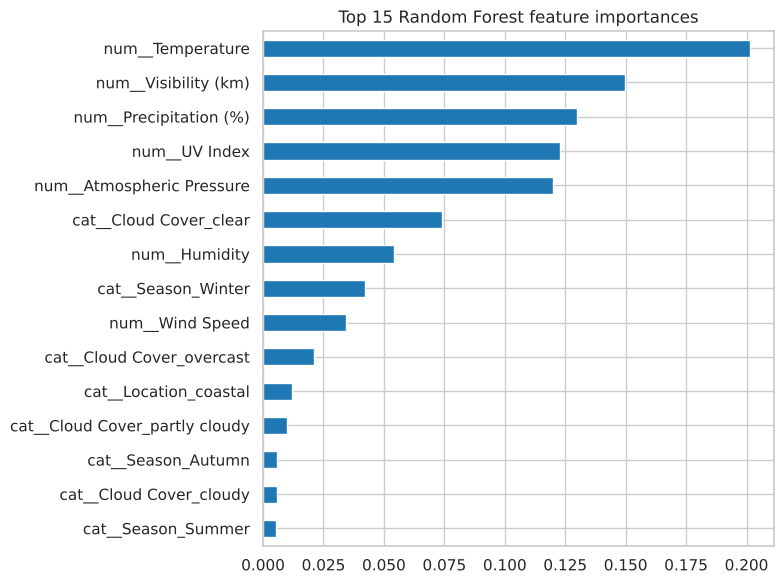

In [11]:
# 9. Robustness: repeat on different random splits (descriptive only) ------------------
rep = []
for s in range(args.splits):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=100 + s)
    dt_s = make_baseline(num_cols, cat_cols).fit(Xa, ya)
    rf_s = make_improved(improved_kind, num_cols, cat_cols, **best_rf_params).fit(Xa, ya)
    rep.append({"split": s, "Baseline accuracy": accuracy_score(yb, dt_s.predict(Xb)),
                "Improved accuracy": accuracy_score(yb, rf_s.predict(Xb))})
rep = pd.DataFrame(rep)
if len(rep):
    rep["Improved - Baseline"] = rep["Improved accuracy"] - rep["Baseline accuracy"]
    rep.round(4).to_csv(f"{out}/repeated_splits.csv", index=False)
    print(f"\nImproved model better in {(rep['Improved - Baseline'] > 0).sum()} of {len(rep)} splits; mean difference = "
          f"{rep['Improved - Baseline'].mean():+.4f}")

# Feature importance (Random Forest only; boosting has no built-in importances)
clf = rf_model.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    feat_names = rf_model.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(clf.feature_importances_, index=feat_names).sort_values(ascending=False)
    imp.round(4).to_csv(f"{out}/feature_importance.csv")
    plt.figure(figsize=(8, 6)); imp.head(15)[::-1].plot.barh(color="tab:blue")
    plt.title(f"Top 15 {improved_kind} feature importances")
    plt.tight_layout(); plt.savefig(f"{out}/feature_importance.png", dpi=150); plt.show()

## 10. Final results and conclusion

In [12]:
# 10. Final table and conclusion -----------------------------------------------------
results = pd.DataFrame({
    "Baseline (Logistic Regression)": [f"{acc_dt:.4f}", f"[{lo_dt:.4f}, {hi_dt:.4f}]"],
    "Improved model": [f"{acc_rf:.4f}", f"[{lo_rf:.4f}, {hi_rf:.4f}]"],
    "Difference (Improved - Baseline)": [f"{diff:+.4f}", f"[{lo_d:+.4f}, {hi_d:+.4f}]"]},
    index=["Accuracy", "95% CI"])
results.to_csv(f"{out}/final_results_table.csv")
print("\nFinal results:\n", results.to_string())

lines = [f"Improved model accuracy {acc_rf:.4f} vs Baseline {acc_dt:.4f} "
         f"(difference {diff:+.4f}, 95% CI [{lo_d:+.4f}, {hi_d:+.4f}]).",
         f"Two-proportion z-test: z = {z:.3f}, p = {p_two:.3g} -> {decision} at alpha = {ALPHA}."]
if decision == "Reject H0" and diff > 0:
    lines.append("CONCLUSION: The improved model is significantly better; the difference is unlikely "
                 "to be due to variation in the test sample.")
elif decision == "Reject H0":
    lines.append("CONCLUSION: The models differ significantly, in favour of the baseline.")
else:
    lines.append("CONCLUSION: We fail to reject H0. The difference is small enough that it could be due to "
                 "variation in the test sample, so we cannot say the improved model is really better.")
conclusion = "\n".join(lines)
print("\n" + conclusion)
with open(f"{out}/conclusion.txt", "w", encoding="utf-8") as f:
    f.write(conclusion)
print(f"\nAll tables and figures saved in '{out}/'.")


Final results:
          Baseline (Logistic Regression)    Improved model Difference (Improved - Baseline)
Accuracy                         0.8667            0.9121                          +0.0455
95% CI                 [0.8537, 0.8796]  [0.9013, 0.9229]               [+0.0286, +0.0623]

Improved model accuracy 0.9121 vs Baseline 0.8667 (difference +0.0455, 95% CI [+0.0286, +0.0623]).
Two-proportion z-test: z = 5.265, p = 1.4e-07 -> Reject H0 at alpha = 0.05.
CONCLUSION: The improved model is significantly better; the difference is unlikely to be due to variation in the test sample.

All tables and figures saved in 'outputs/'.


## Where probability and statistics are used
| Stage | Technique |
|---|---|
| EDA | mean, median, variance, standard deviation, skewness, correlation |
| Preprocessing | median / mode imputation |
| Split | stratified random sampling |
| Random Forest | bootstrap sampling (bagging), majority vote |
| Tuning | k-fold cross-validation |
| Evaluation | accuracy, precision, recall, F1 as estimated probabilities |
| Uncertainty | standard error, normal approximation to the binomial, 95 % CI, bootstrap |
| Decision | two-proportion z-test, p-value, α = 0.05, Type I / II errors |

## 11. Model deployment — "Weather Check" demo app
This section turns the trained models into a small web app (built with **Gradio**), in the style of a clinical-AI demo:

* **Enter observations** by hand, or **try a real example** from the held-out test set (rows neither model saw in training).
* The app shows the **predicted weather type and its probability**, the **probability of every class**, and a **"Show why"** panel per class that tells you which readings drove the decision.
* It also shows the model's **reliability from Section 7**: test accuracy with its 95% confidence interval, and what the other model predicts.

**How "Show why" works (local occlusion explanation):** each reading is, one at a time, replaced by a typical training value (median, or most common category) and the change in the class probability is measured. A large drop means that reading pushed the model towards that class.

In [13]:
import sys, html, joblib

# ---- save the trained models + everything the app needs (this file is the deployable artefact) ----
FEATURES = list(X.columns)
BASELINE_ROW = {c: (X_train[c].median() if c in num_cols else X_train[c].mode()[0]) for c in FEATURES}
RANGES = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in num_cols}
CATEGORIES = {c: sorted(X_train[c].dropna().unique().tolist()) for c in cat_cols}
MODELS = {"Random Forest (improved)": rf_model, "Logistic Regression (baseline)": dt_model}
RELIABILITY = {"Random Forest (improved)": (acc_rf, lo_rf, hi_rf),   # accuracy and 95% CI from Section 7
               "Logistic Regression (baseline)": (acc_dt, lo_dt, hi_dt)}
joblib.dump({"models": MODELS, "features": FEATURES, "baseline_row": BASELINE_ROW, "ranges": RANGES,
             "categories": CATEGORIES, "reliability": RELIABILITY, "pct_cols": pct_cols},
            "outputs/weather_check_models.joblib")
print("Saved deployable model bundle -> outputs/weather_check_models.joblib")

ICON = {"Sunny": "☀️", "Cloudy": "☁️", "Rainy": "🌧️", "Snowy": "❄️"}
DESC = {"Sunny": "clear skies and strong sunshine", "Cloudy": "cloud cover with little or no precipitation",
        "Rainy": "precipitation falling as rain", "Snowy": "cold conditions with precipitation as snow"}

def make_row(values):
    # Build a one-row DataFrame from form values, applying the same cleaning rule as training
    row = {}
    for c, v in zip(FEATURES, values):
        if c in num_cols:
            row[c] = np.nan if v is None or v == "" else float(v)
        else:
            row[c] = v
    return pd.DataFrame([row], columns=FEATURES)

def input_warnings(row):
    notes = []
    for c in num_cols:
        v = row[c].iloc[0]
        if pd.isna(v):
            notes.append(f"<b>{html.escape(c)}</b> is missing; the training median is used instead.")
            continue
        if c in pct_cols and not (0 <= v <= 100):
            notes.append(f"<b>{html.escape(c)}</b> = {v:g} is outside 0–100%, so it is treated as missing (as in training).")
            row.loc[row.index[0], c] = np.nan
            continue
        lo, hi = RANGES[c]
        if v < lo or v > hi:
            notes.append(f"<b>{html.escape(c)}</b> = {v:g} is outside the training range [{lo:g}, {hi:g}]; "
                         "the prediction is an extrapolation.")
    return row, notes

def explain(model, row):
    # Occlusion: replace one feature at a time by its typical training value and measure the change
    variants = [row] + [row.assign(**{c: BASELINE_ROW[c]}) for c in FEATURES]
    P = model.predict_proba(pd.concat(variants, ignore_index=True))
    return model.classes_, P[0], pd.DataFrame(P[0] - P[1:], index=FEATURES, columns=model.classes_)

# ---------- HTML rendering (dark theme, inline styles so it works inside Gradio and Jupyter) ----------
FONT = "font-family:Inter,Segoe UI,Helvetica,Arial,sans-serif;"
CARD = ("background:#1b1b1e;border:1px solid #34343a;border-radius:12px;padding:18px 20px;"
        "margin:12px 0;color:#e7e7ea;" + FONT)
ORANGE, MUTED = "#fb923c", "#a1a1aa"

def header_html():
    return (f'<div style="{FONT}color:#f4f4f5;padding:4px 2px">'
            '<div style="font-size:30px;font-weight:800">Weather Check</div>'
            f'<div style="color:{MUTED};margin:4px 0 12px">Give it a set of weather readings. The model says '
            'which weather type it detects and shows which readings led it there.</div>'
            '<div style="background:#3b1414;border:1px solid #7f1d1d;color:#fca5a5;border-radius:8px;'
            'padding:10px 14px;font-size:13px">Classroom prototype trained on the synthetic Kaggle '
            '<i>Weather Type Classification</i> dataset. It classifies current conditions; it is not a '
            'forecast and must not be used for safety decisions.</div></div>')

def fmt_value(c, v):
    if c in num_cols:
        return "missing" if pd.isna(v) else f"{v:g}"
    return html.escape(str(v))

def why_panel(cls, deltas, row):
    d = deltas[cls].sort_values(key=np.abs, ascending=False).head(5)
    scale = max(d.abs().max(), 1e-9)
    items = []
    for feat, val in d.items():
        w = abs(val) / scale * 48
        col = "#22c55e" if val > 0 else "#ef4444"
        side = f"left:50%;width:{w:.1f}%" if val > 0 else f"left:{50 - w:.1f}%;width:{w:.1f}%"
        verb = "pushes towards" if val > 0 else "pushes away from"
        items.append(
            '<div style="display:grid;grid-template-columns:200px 1fr 70px;gap:10px;align-items:center;margin:6px 0">'
            f'<div style="font-size:13px">{html.escape(feat)} = <b>{fmt_value(feat, row[feat].iloc[0])}</b></div>'
            '<div style="position:relative;height:10px;background:#2a2a2f;border-radius:5px">'
            '<div style="position:absolute;left:50%;top:-3px;width:1px;height:16px;background:#71717a"></div>'
            f'<div style="position:absolute;{side};height:10px;background:{col};border-radius:5px"></div></div>'
            f'<div style="font-size:12px;color:{col};text-align:right" title="{verb} {cls}">'
            f'{val * 100:+.1f} pts</div></div>')
    if d.abs().max() < 1e-6:
        items = [f'<div style="font-size:13px;color:{MUTED}">No single reading changes this probability on its own.</div>']
    return (f'<div style="margin:8px 0 4px;padding:10px 12px;background:#141416;border-radius:8px">'
            f'<div style="font-size:12px;color:{MUTED};margin-bottom:4px">Top readings for <b>{cls}</b>. '
            'Green = pushes towards this class, red = pushes away. Points = change in probability when the '
            'reading is replaced by a typical training value.</div>' + "".join(items) + "</div>")

def render_result(row, model_name, actual=None, source="Your observation"):
    row, notes = input_warnings(row.copy())
    model = MODELS[model_name]
    classes, probs, deltas = explain(model, row)
    k = int(np.argmax(probs)); pred = classes[k]

    other_name = [m for m in MODELS if m != model_name][0]
    other_p = MODELS[other_name].predict_proba(row)[0]
    other_pred = MODELS[other_name].classes_[int(np.argmax(other_p))]

    out = [f'<div style="{CARD}"><div style="font-size:18px;font-weight:700;margin-bottom:12px">'
           f'Result for {html.escape(source)}</div>'
           f'<div style="background:#3a1f0c;border:1px solid #7c2d12;color:{ORANGE};border-radius:8px;'
           f'padding:14px 16px;font-size:21px;font-weight:600">{ICON.get(pred, "")} The {model_name.split(" (")[0]} '
           f'predicts <b>{html.escape(str(pred))}</b> ({probs[k]:.0%}).</div>']
    sub = []
    if actual is not None:
        ok = (actual == pred)
        sub.append(f'Recorded label: <b>{html.escape(str(actual))}</b> '
                   f'<span style="color:{"#22c55e" if ok else "#ef4444"}">'
                   f'{"✓ correct" if ok else "✗ incorrect"}</span>.')
    agree = "agrees" if other_pred == pred else "disagrees"
    sub.append(f'{other_name} {agree}: it predicts <b>{html.escape(str(other_pred))}</b> ({other_p.max():.0%}).')
    acc, lo, hi = RELIABILITY[model_name]
    sub.append(f'Reliability on held-out test data: correct {acc:.1%} of the time '
               f'(95% CI {lo:.1%} – {hi:.1%}).')
    out.append(f'<div style="color:{MUTED};font-size:13px;margin-top:10px;line-height:1.6">' + "<br>".join(sub) + "</div>")
    if notes:
        out.append('<div style="margin-top:10px;background:#3a300c;border:1px solid #854d0e;color:#fde68a;'
                   'border-radius:8px;padding:8px 12px;font-size:13px">' + "<br>".join(notes) + "</div>")
    out.append("</div>")

    out.append(f'<div style="{CARD}"><div style="font-size:18px;font-weight:700">What the model checked for</div>'
               f'<div style="color:{MUTED};font-size:13px;margin:6px 0 10px">Each bar is how likely the model thinks '
               'that weather type is. The highest bar is the prediction. Open <b>Show why</b> to see which readings '
               'drove each probability.</div>')
    for i, cls in enumerate(classes):
        fill = ORANGE if i == k else "#71717a"
        out.append(
            '<div style="border-top:1px solid #2a2a2f;padding:10px 0">'
            '<div style="display:grid;grid-template-columns:210px 1fr 60px;gap:14px;align-items:center">'
            f'<div><div style="font-weight:600">{ICON.get(cls, "")} {html.escape(str(cls))}</div>'
            f'<div style="color:{MUTED};font-size:12px">{DESC.get(cls, "")}</div></div>'
            '<div style="height:12px;background:#2a2a2f;border-radius:6px;overflow:hidden">'
            f'<div style="width:{probs[i] * 100:.1f}%;height:12px;background:{fill};border-radius:6px"></div></div>'
            f'<div style="text-align:right;font-weight:600">{probs[i]:.0%}</div></div>'
            f'<details style="margin-top:4px"><summary style="cursor:pointer;color:{ORANGE};font-size:13px;'
            f'font-weight:600">Show why</summary>{why_panel(cls, deltas, row)}</details></div>')
    out.append("</div>")
    return '<div style="max-width:980px">' + "".join(out) + "</div>"

# ---------- curated "real examples" from the held-out test set ----------
rng_ex = np.random.default_rng(SEED)
ex_ids = []
for cls in labels:
    ex_ids += rng_ex.choice(y_test.index[(y_test == cls).to_numpy()], 3, replace=False).tolist()
disagree_ids = y_test.index[y_pred_dt != y_pred_rf].tolist()[:4]
rf_wrong_ids = y_test.index[y_pred_rf != y_test.to_numpy()].tolist()[:3]
EXAMPLES = {}
for i in dict.fromkeys(ex_ids + disagree_ids + rf_wrong_ids):
    tag = " · hard case" if i in rf_wrong_ids else (" · models disagree" if i in disagree_ids else "")
    EXAMPLES[f"{ICON.get(y_test.loc[i], '')} {y_test.loc[i]} — test row {i}{tag}"] = i
print(f"{len(EXAMPLES)} demo examples prepared from the held-out test set.")

# ---------- static preview (also a fallback if the web app cannot launch) ----------
first = next(iter(EXAMPLES.values()))
preview = header_html() + render_result(X_test.loc[[first]], "Random Forest (improved)",
                                        actual=y_test.loc[first], source=f"held-out test row {first}")
with open("outputs/demo_preview.html", "w", encoding="utf-8") as f:
    f.write(f'<html><head><meta charset="utf-8"></head><body style="background:#0f0f11;padding:24px">{preview}</body></html>')
if "ipykernel" in sys.modules:
    from IPython.display import HTML
    display(HTML(f'<div style="background:#0f0f11;padding:16px;border-radius:12px">{preview}</div>'))
else:
    print("Static preview saved -> outputs/demo_preview.html")

Saved deployable model bundle -> outputs/weather_check_models.joblib
17 demo examples prepared from the held-out test set.


## 12. (Optional) Download all figures and tables for the report

In [14]:
import shutil
shutil.make_archive("outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("Saved outputs.zip in the working folder.")

Saved outputs.zip in the working folder.


## 13. Launch the interactive Weather Check app
Run this cell: the app appears below the cell and Gradio prints a **public `*.gradio.live` link** (valid ~72 hours) that you can open on any device or share for the demo. Stop it with the ■ stop button.

In [ ]:
def on_classify(*args):
    *vals, model_name = args
    return render_result(make_row(vals), model_name, source="your observation")

def on_example(label, model_name):
    i = EXAMPLES[label]
    row = X_test.loc[[i]]
    vals = [None if pd.isna(v) else (float(v) if c in num_cols else v) for c, v in zip(FEATURES, row.iloc[0])]
    return [*vals, render_result(row, model_name, actual=y_test.loc[i], source=f"held-out test row {i}")]

def launch_app(share):
    import subprocess, inspect
    try:
        import gradio as gr
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
        import gradio as gr

    # Gradio moved theme/js from Blocks() to launch() in newer versions: pass them wherever they are accepted
    DARK_JS = "() => { document.body.classList.add('dark'); }"
    style = {"theme": gr.themes.Soft(primary_hue="orange", neutral_hue="zinc"), "js": DARK_JS}
    launch_params = inspect.signature(gr.Blocks.launch).parameters
    blocks_kw = {k: v for k, v in style.items() if k not in launch_params}
    launch_kw = {k: v for k, v in style.items() if k in launch_params}

    with gr.Blocks(title="Weather Check", **blocks_kw) as demo:
        gr.HTML(header_html())
        with gr.Row(equal_height=False):
            with gr.Column(scale=3):
                gr.Markdown("### 1. Enter weather observations")
                inputs = []
                with gr.Row():
                    for c in num_cols:
                        lo, hi = RANGES[c]
                        inputs.append(gr.Number(label=c, value=float(BASELINE_ROW[c]),
                                                info=f"training range {lo:g} to {hi:g}", min_width=150))
                with gr.Row():
                    for c in cat_cols:
                        inputs.append(gr.Dropdown(CATEGORIES[c], value=BASELINE_ROW[c], label=c, min_width=150))
                # put inputs back in the original feature order expected by make_row
                order = {c: i for i, c in enumerate(num_cols + cat_cols)}
                inputs = [inputs[order[c]] for c in FEATURES]
                model_choice = gr.Radio(list(MODELS), value="Random Forest (improved)", label="Model")
                classify_btn = gr.Button("Classify weather", variant="primary")
            with gr.Column(scale=2):
                gr.Markdown("### …or try a real example\nHeld-out test observations that neither model saw while "
                            "learning. *Hard case* = the Random Forest gets it wrong; *models disagree* = the two "
                            "models give different answers.")
                example_choice = gr.Dropdown(list(EXAMPLES), value=list(EXAMPLES)[0], label="Test-set example")
                example_btn = gr.Button("Analyse example", variant="primary")
        result = gr.HTML()

        classify_btn.click(on_classify, inputs=inputs + [model_choice], outputs=result)
        example_btn.click(on_example, inputs=[example_choice, model_choice], outputs=inputs + [result])
    demo.launch(share=share, debug=False, **launch_kw)
    return demo

IN_NOTEBOOK = "ipykernel" in sys.modules
if IN_NOTEBOOK or "--demo" in sys.argv:
    demo = launch_app(share=IN_NOTEBOOK)
else:
    print("Run `python weather_ml_stats.py --demo` to start the Weather Check web app locally.")